# Kinora growth analysis: walkthrough

This notebook walks through the main results of the project in order. The heavy lifting
lives in the `growth_analytics` package and the SQL files in `sql/`. Here I call those
functions and comment on what comes out.

The data is simulated (see `docs/methodology.md`). Kinora is a fictional freemium
fitness app. To run this notebook, first run `make data warehouse analysis`.

In [1]:
import json
import warnings

import pandas as pd
from IPython.display import Image, display

from growth_analytics import config as C
from growth_analytics import churn_model, experiments as E, funnel as F, marketing as MK
from growth_analytics.warehouse import read

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_columns", 20)
FIG = C.FIGURES_DIR

def show(name, width=900):
    display(Image(filename=str(FIG / f"{name}.png"), width=width))

## 1. The data

Six raw tables are loaded into DuckDB as staging views, then modelled into a user-day
fact table, a user dimension and a set of marts.

In [2]:
read("""
SELECT table_name, estimated_size AS rows
FROM duckdb_tables()
ORDER BY table_name
""")

,table_name,rows
0,dim_users,149317
1,fct_user_daily,1044874
2,mart_activation,130538
3,mart_channel_daily,1188
4,mart_channel_economics,5
5,mart_churn_features,4943
6,mart_cohort_retention,155
7,mart_engagement_daily,396
8,mart_engagement_monthly,13
9,mart_exp_onboarding,13860


In [3]:
read("""
SELECT event_name, count(*) AS events, count(DISTINCT user_id) AS users
FROM stg_events
GROUP BY 1
ORDER BY 2 DESC
""")

,event_name,events,users
0,app_open,2060585,149317
1,workout_started,1540150,122860
2,workout_completed,1225784,111058
3,onboarding_step,576323,149317
4,signup,149317,149317
5,onboarding_complete,86048,86048
6,paywall_view,85720,85720
7,trial_start,16545,16545
8,subscription_renewal,16438,3308
9,subscription_start,9587,9587


## 2. Engagement and retention

About a third of new users come back in their second week, and roughly one in seven is
still active a month later. Retention differs a lot by acquisition channel.

In [4]:
read("""
SELECT avg(d7_retained::INT)  FILTER (WHERE d7_mature)  AS d7_retention,
       avg(d30_retained::INT) FILTER (WHERE d30_mature) AS d30_retention
FROM dim_users
""")

,d7_retention,d30_retention
0,0.3505,0.1460


In [5]:
rc = read("mart_retention_curve")
rc.pivot(index="acquisition_channel", columns="day_n", values="retention_rate").round(3)

day_n,1,7,14,30,60,90
acquisition_channel,,,,,,
influencer,0.4820,0.2730,0.1850,0.0980,0.0450,0.0250
organic,0.6170,0.3950,0.2840,0.1710,0.0870,0.0530
paid_social,0.5010,0.2930,0.1970,0.1090,0.0520,0.0310
referral,0.6790,0.4560,0.3440,0.2200,0.1220,0.0750
search,0.5920,0.3660,0.2660,0.1580,0.0830,0.0470


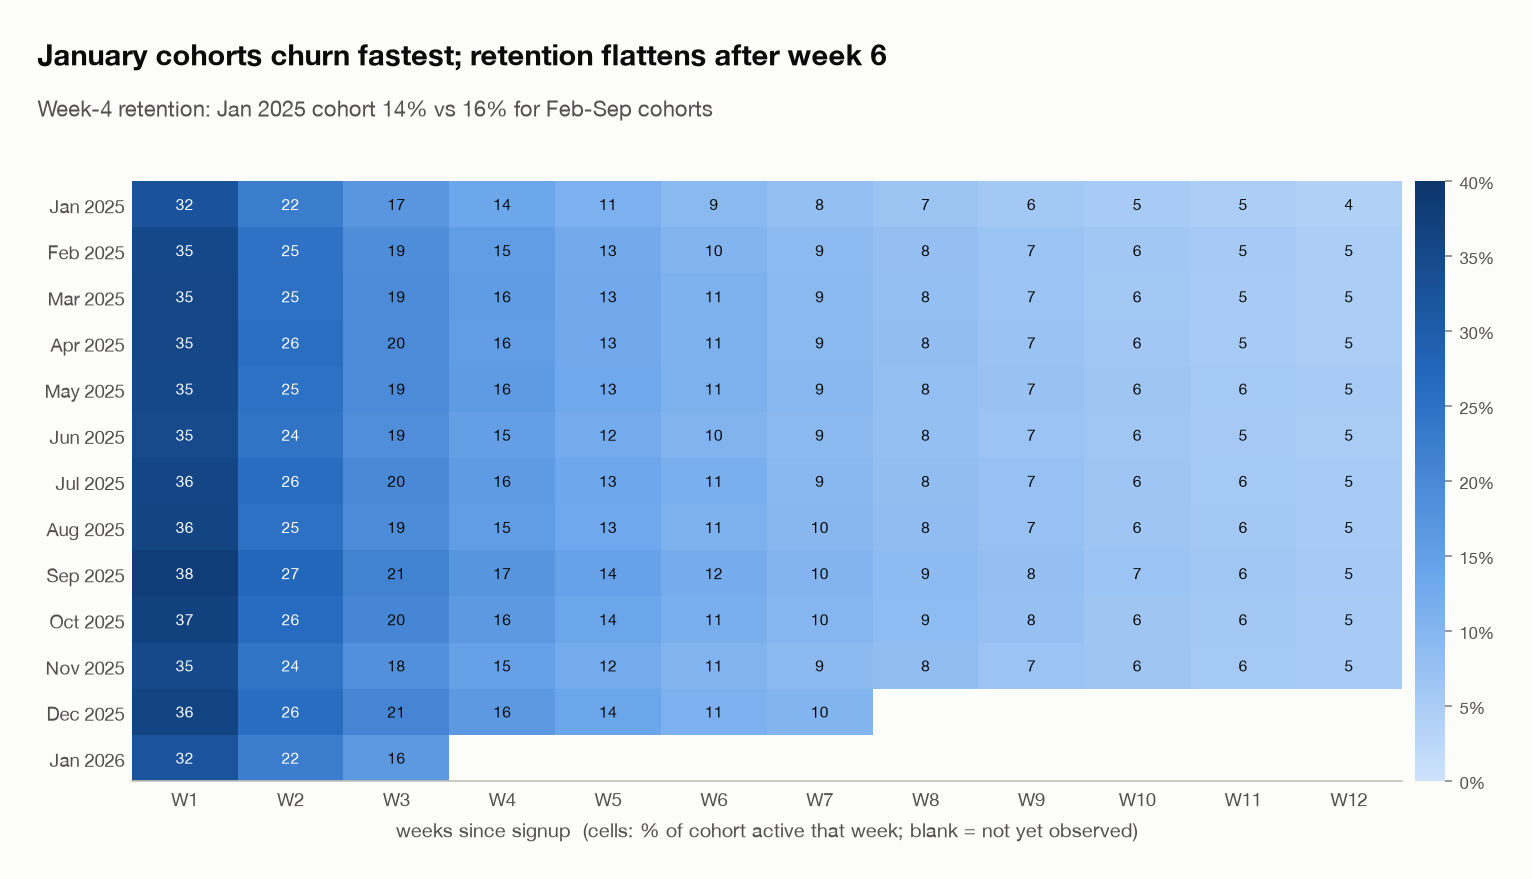

In [6]:
show('04_cohort_retention')

## 3. Funnel and the "aha moment"

The biggest drop in the funnel is from paywall to trial. On the activation side, I scanned
simple rules of the form "at least k active days (or workouts) in the first week" and kept
the one that best separates users who are still active at D30.

In [7]:
F.funnel_table(read("mart_funnel")).round(3)

,stage,users,step_conversion,cumulative_conversion
0,Signed up,130538,NaN,1.0000
1,Completed onboarding,75646,0.5790,0.5790
2,Saw paywall,75345,0.9960,0.5770
3,Started free trial,14643,0.1940,0.1120
4,Became paying subscriber,8725,0.5960,0.0670


In [8]:
act = read("mart_activation")
best = F.best_activation_rule(act)
best

{'feature': 'active_days_first_7d',
 'k': 3,
 'youden_j': 0.5296489481508069,
 'share_users_reaching': 0.3657708866383735,
 'retention_if_reached': 0.3264917167570737,
 'retention_if_not': 0.04186445386575836,
 'retention_ratio': 7.798781223899276}

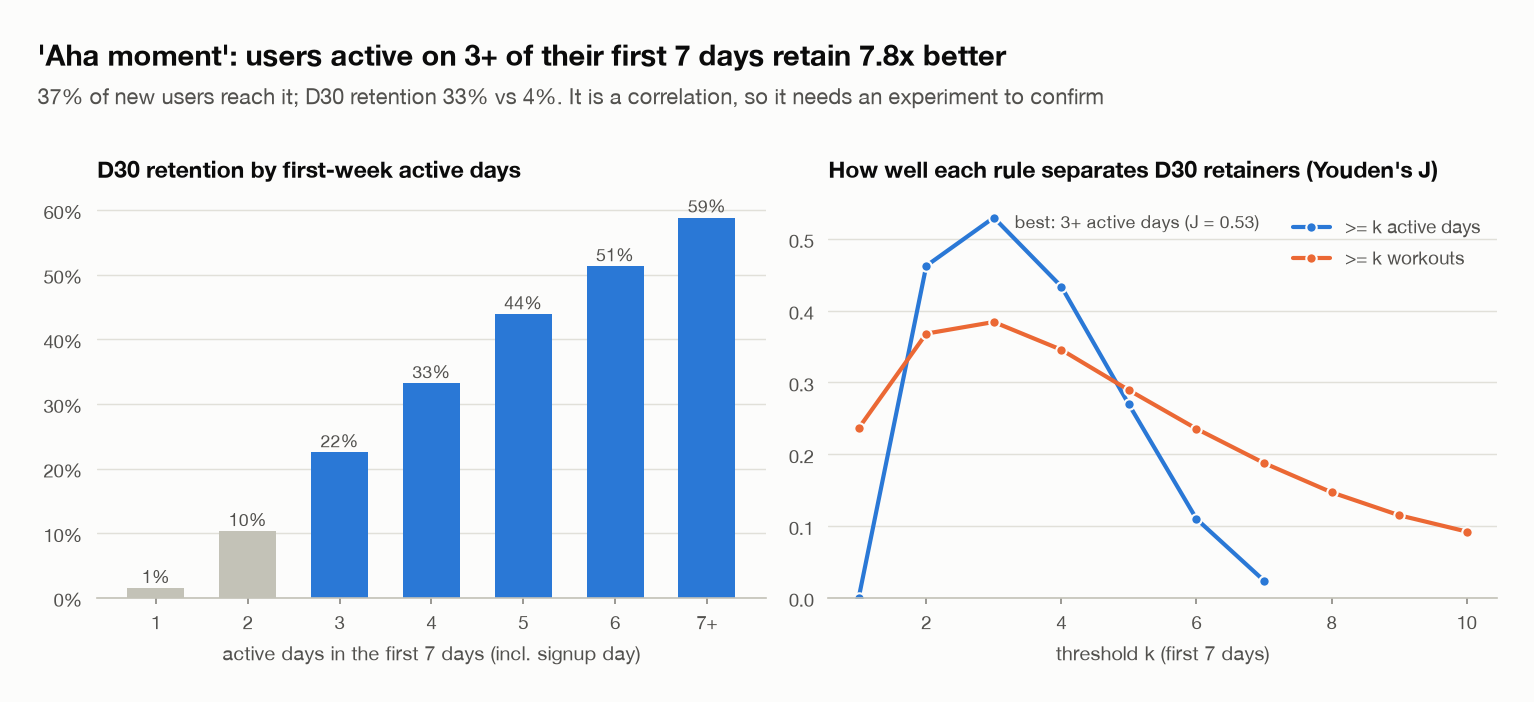

In [9]:
show('06_activation_threshold')

This is a correlation. Users who come back three times in week one are also the more
motivated users to begin with, so the next step would be an experiment that nudges new
users towards a second and third session.

## 4. Experiment 1: onboarding v2

New users were split 50/50 between the old 5-step onboarding and a shorter 3-step flow.
The primary metric is D7 retention. Before looking at results I sized the test from
July and August cohorts.

In [10]:
pre = read("""
SELECT signup_date, platform, d7_retained::INT AS d7_retained FROM dim_users
WHERE signup_date BETWEEN DATE '2025-07-01' AND DATE '2025-08-31' AND platform IN ('ios', 'android')
""")
E.power_analysis(pre)

{'baseline_cohorts': 'mobile signups 2025-07-01 to 2025-08-31',
 'baseline_d7': 0.36647062182378803,
 'mde_abs': 0.025,
 'mde_rel': 0.06821829230289811,
 'alpha': 0.05,
 'power': 0.8,
 'n_per_arm': 5908,
 'daily_eligible_signups': 282.46774193548384,
 'runtime_days_needed': 42,
 'runtime_days_planned': 42}

The first check is the sample ratio. iOS and Android are fine, but web has far fewer
treatment users than control.

In [11]:
e1 = E.analyze_onboarding(read("mart_exp_onboarding"))
pd.DataFrame(e1["srm_by_platform"]).T[["n_control", "n_treatment", "share_treatment", "p_value"]]

,n_control,n_treatment,share_treatment,p_value
ios,2812.0000,2843.0000,0.5027,0.6802
android,3505.0000,3497.0000,0.4994,0.9238
web,816.0000,387.0000,0.3217,0.0000


The new web flow logged its exposure event late, so users who bounced quickly were often
missing from the treatment group. The users that remain are the more engaged ones, which
inflates the web result. I excluded web and analysed iOS and Android only.

In [12]:
cols = ["metric", "control", "treatment", "abs_diff", "ci_low", "ci_high", "p_value"]
rows = [e1["web_only_primary"], e1["naive_primary"], e1["primary"], *e1["secondary"], *e1["guardrails"]]
pd.DataFrame(rows)[cols]

,metric,control,treatment,abs_diff,ci_low,ci_high,p_value
0,"D7 retention (web only, biased)",0.2696,0.3876,0.1180,0.0607,0.1753,0.0000
1,"D7 retention (all platforms, naive)",0.3602,0.4037,0.0436,0.0274,0.0598,0.0000
2,D7 retention,0.3719,0.4047,0.0329,0.0159,0.0498,0.0001
3,Onboarding completion,0.6001,0.7246,0.1245,0.1081,0.1408,0.0000
4,Trial start <= 7 days,0.1228,0.1350,0.0122,0.0005,0.0238,0.0410
5,D30 retention,0.1570,0.1798,0.0228,0.0097,0.0358,0.0006
6,Trial-to-paid conversion,0.6057,0.5783,-0.0274,-0.0751,0.0203,0.2608
7,Crashes per session (7d),0.0040,0.0041,0.0002,-0.0009,0.0012,0.7548


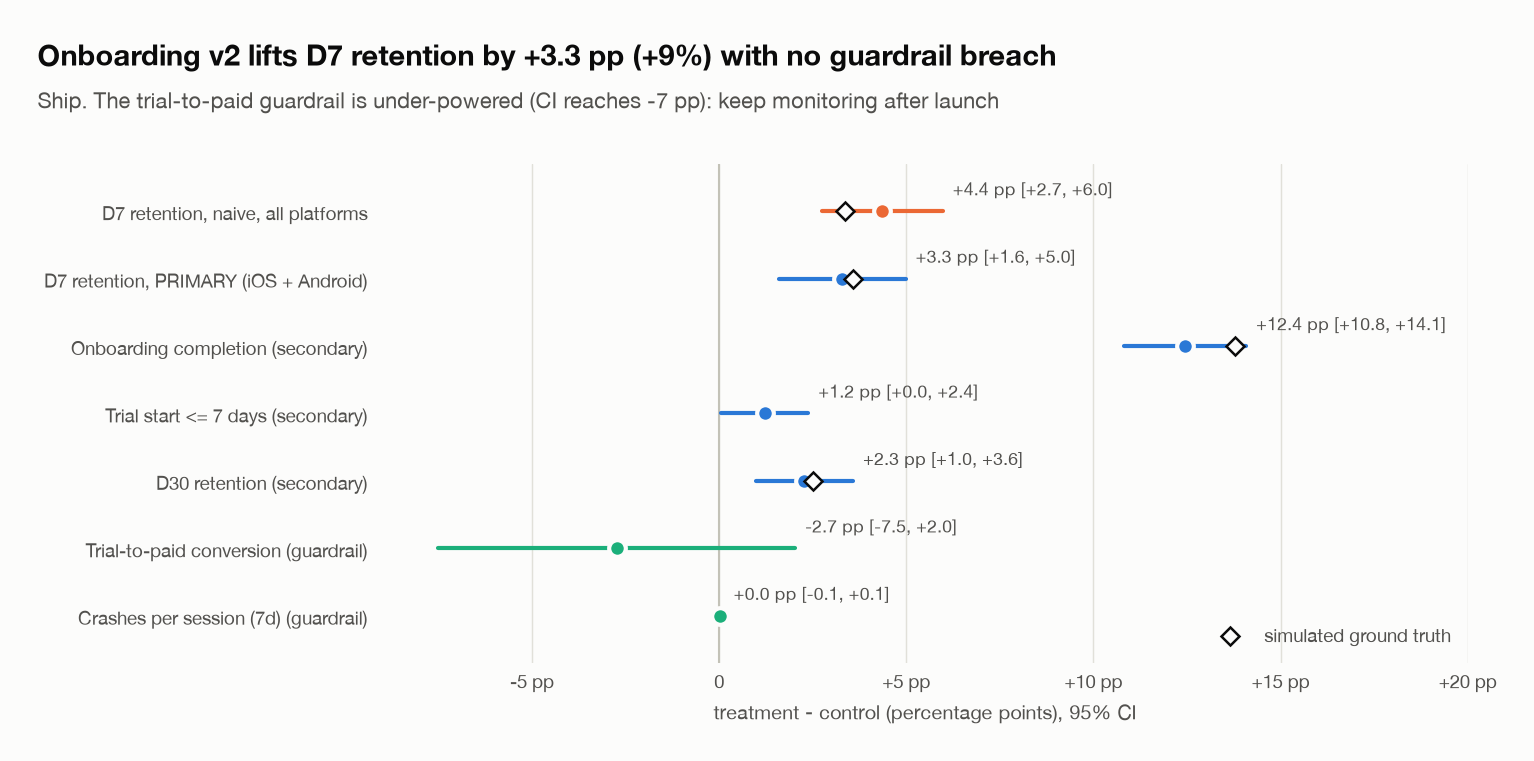

In [13]:
show('08_exp1_effects')

In [14]:
pd.DataFrame(e1["segments"])[["dimension", "segment", "abs_diff", "ci_low", "ci_high", "p_value", "p_bh"]]

,dimension,segment,abs_diff,ci_low,ci_high,p_value,p_bh
0,platform,android,0.0520,0.0294,0.0745,0.0000,0.0000
1,platform,ios,0.0089,-0.0168,0.0346,0.4962,0.4962
2,acquisition_channel,influencer,0.0537,0.0100,0.0974,0.0161,0.0377
3,acquisition_channel,organic,0.0163,-0.0139,0.0465,0.2898,0.3381
4,acquisition_channel,paid_social,0.0302,0.0006,0.0597,0.0455,0.0796
5,acquisition_channel,referral,0.0312,-0.0250,0.0873,0.2768,0.3381
6,acquisition_channel,search,0.0652,0.0191,0.1113,0.0057,0.0200


The lift is concentrated on Android. The interaction test (Android lift minus iOS lift)
is significant, while the channel splits are exploratory and BH-adjusted.

Decision: ship to iOS and Android, fix the web logging and re-test web separately. The
trial-to-paid guardrail did not move significantly, but its CI is wide, so I would keep
watching it after launch.

## 5. Experiment 2: smart reminders

Existing users were split 50/50, and treatment users got reminders timed to when they
usually work out. The metric is workouts per user over 28 days, which is heavy-tailed.

In [15]:
e2 = E.analyze_reminders(read("mart_exp_reminders"), n_boot=2000)
e2["distribution"]

{'mean': 7.448084677419355,
 'median': 1.0,
 'p99': 51.0,
 'share_zero': 0.4880712365591398,
 'top10pct_share_of_workouts': 0.4652274931763326,
 'skewness': 2.382949748993102}

In [16]:
pd.DataFrame([e2["pre_period_balance"], e2["raw"], e2["cuped"]])[cols]

,metric,control,treatment,abs_diff,ci_low,ci_high,p_value
0,Pre-period workouts (A/A),10.5989,11.2853,0.6864,0.1071,1.2658,0.0202
1,"Workouts / user (28d), raw",6.8895,8.0040,1.1145,0.5292,1.6998,0.0002
2,"Workouts / user (28d), CUPED",6.8895,7.4836,0.5940,0.2066,0.9815,0.0027


By chance, the treatment group was already more active before launch. The raw comparison
mixes that head start with the real effect. CUPED adjusts for pre-period workouts, which
removes most of the imbalance and also cuts the variance roughly in half.

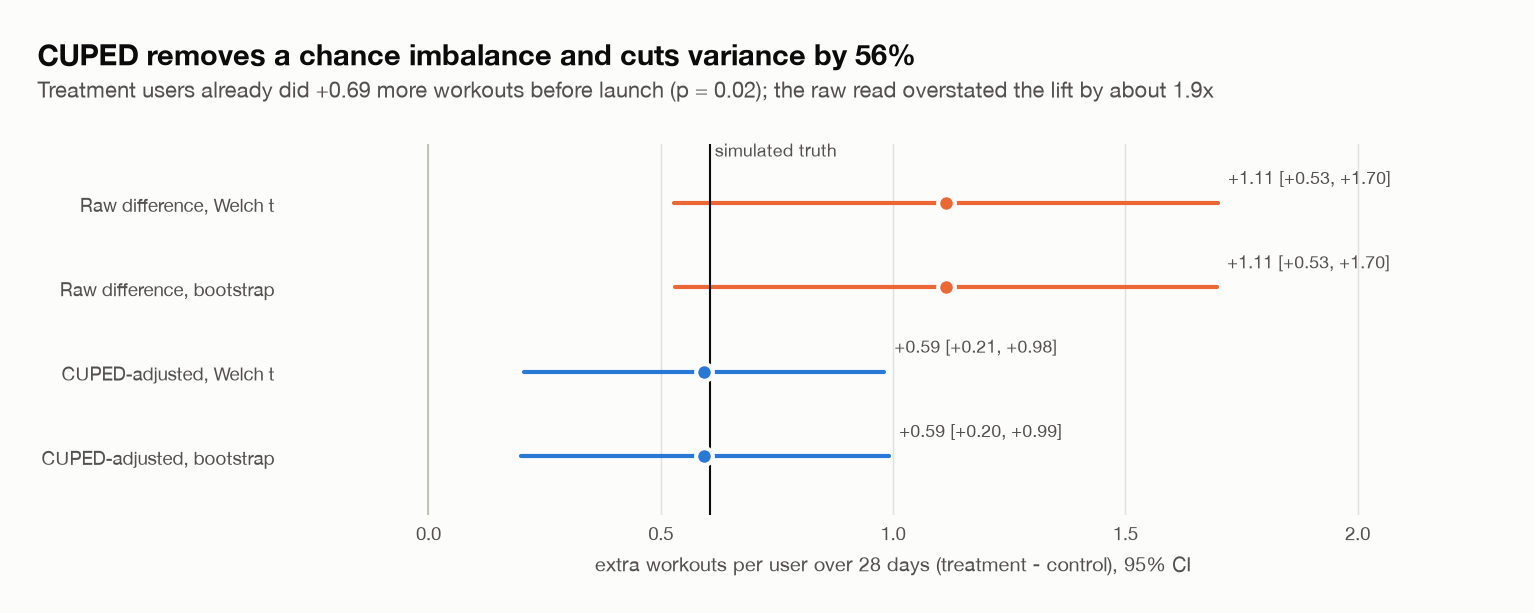

In [17]:
show('10_exp2_cuped')

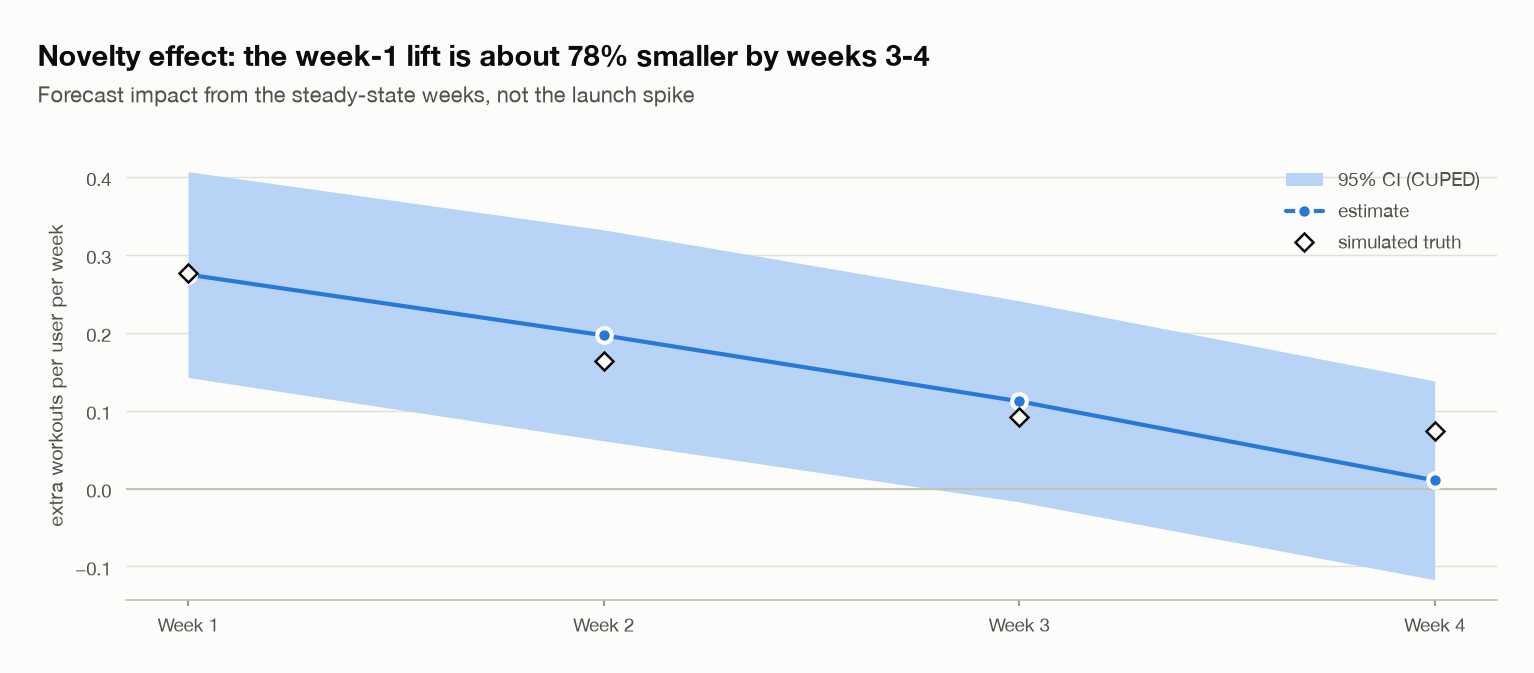

In [18]:
show('11_exp2_novelty')

Most of the lift comes in the first week and fades after that. For a forecast I would use
the weeks 3-4 effect, not the 28-day average.

## 6. Churn model

The model scores monthly subscribers on day 14 and predicts whether they cancel before the
first renewal. It is trained on subscriptions that started before September and tested on
later ones.

In [19]:
res = churn_model.run(read("mart_churn_features"))
pd.DataFrame(res.summary["models"]).T

,cv_roc_auc,test_roc_auc,test_pr_auc,test_brier
Logistic regression,0.7044,0.7221,0.5512,0.2003
Gradient boosting,0.6754,0.7032,0.5291,0.2062


In [20]:
res.deciles

,decile,users,churn_rate,avg_score,lift,cum_capture
0,1,161,0.6211,0.6504,1.6871,0.1689
1,2,161,0.4845,0.5815,1.3159,0.3007
2,3,161,0.5714,0.5345,1.5521,0.4561
3,4,160,0.5062,0.4919,1.3751,0.5929
4,5,161,0.4596,0.4345,1.2484,0.7179
5,6,161,0.3602,0.3581,0.9785,0.8159
6,7,160,0.2812,0.2833,0.7639,0.8919
7,8,161,0.1988,0.2150,0.5399,0.9459
8,9,161,0.1366,0.1638,0.3712,0.9831
9,10,161,0.0621,0.1054,0.1687,1.0000


In [21]:
res.summary["policy"]

{'threshold': 0.31,
 'breakeven_probability': 0.3257132086223205,
 'share_targeted': 0.6169154228855721,
 'value_per_1k_model': 1265.230149253731,
 'value_per_1k_target_all': 512.2082835820894,
 'value_per_1k_target_none': 0.0,
 'assumptions': {'discount_usd': 6.5,
  'save_rate': 0.3,
  'redeem_rate_non_churners': 0.6,
  'extra_months_if_saved': 3.0},
 'uplift_vs_target_all': 753.0218656716416}

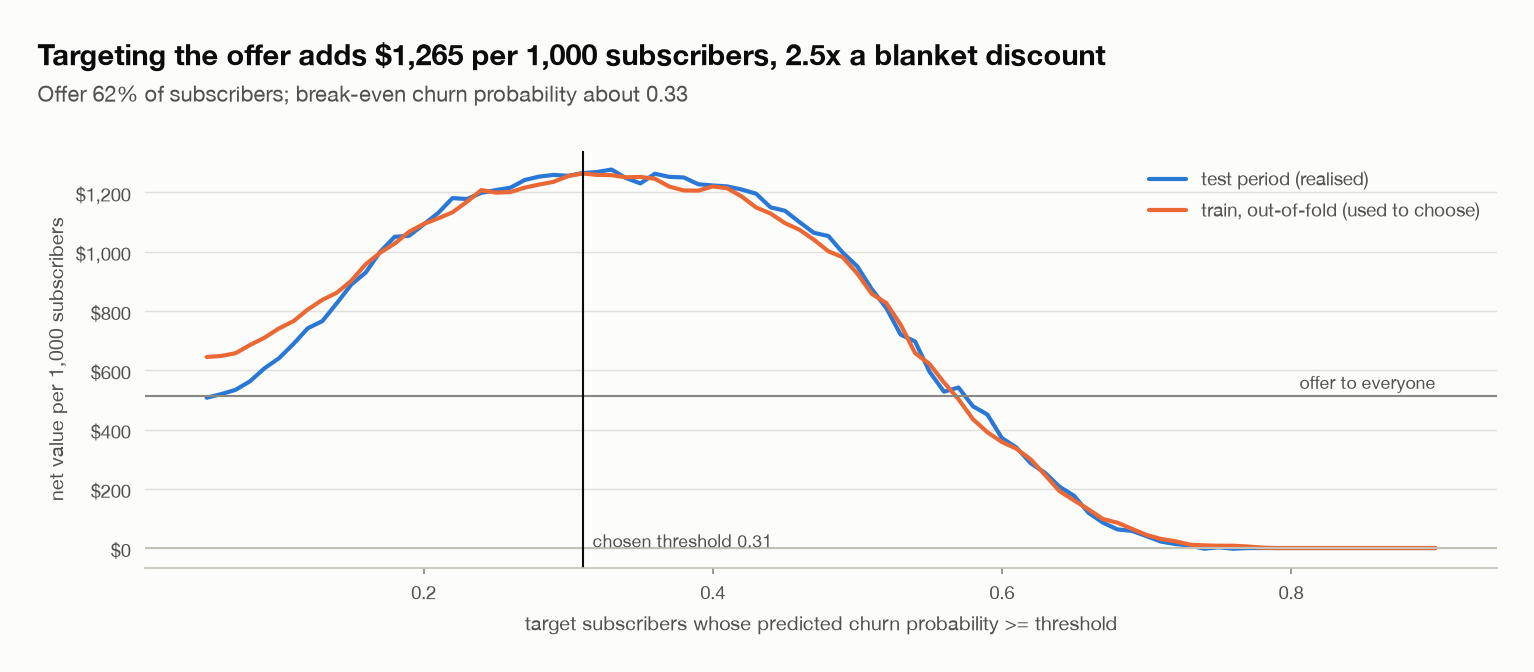

In [22]:
show('16_retention_offer_policy')

Logistic regression did slightly better than gradient boosting here, and it is easier to
explain. The useful output is the targeting rule: offering the discount only to
subscribers above the threshold is worth much more than offering it to everyone.

## 7. Marketing efficiency

In [23]:
econ = read("mart_channel_economics")
econ[["channel", "spend_usd", "paid_subscribers", "cac_usd", "ltv_24m_usd", "ltv_to_cac", "payback_months"]]

,channel,spend_usd,paid_subscribers,cac_usd,ltv_24m_usd,ltv_to_cac,payback_months
0,influencer,107755.9200,855,126.0303,80.2683,0.6369,NaN
1,organic,0.0000,3639,NaN,98.0900,NaN,NaN
2,paid_social,142574.4900,2174,65.5816,83.2183,1.2689,13.1892
3,referral,0.0000,1330,NaN,112.9053,NaN,NaN
4,search,70239.1100,1589,44.2033,99.1388,2.2428,6.5557


In [24]:
curves = MK.response_curves(read("mart_channel_daily"))
opt = MK.optimise_budget(econ, curves)
display(curves[["channel", "elasticity", "elasticity_ci_low", "elasticity_ci_high", "marginal_cost_per_signup"]])
{k: v for k, v in opt.items() if k != "table"}

,channel,elasticity,elasticity_ci_low,elasticity_ci_high,marginal_cost_per_signup
0,paid_social,0.8319,0.7431,0.9207,3.8576
1,search,0.7546,0.6178,0.8913,3.9618
2,influencer,0.8555,0.8317,0.8794,6.5462


{'budget': 320569.51999999996,
 'paid_subscribers_change': 499.72016760825227,
 'paid_subscribers_change_pct': 0.10821138319797585,
 'ltv_change_usd': 60096.54691111902,
 'ltv_change_pct': 0.14762922429075664,
 'blended_cac_old': 69.41739281074057,
 'blended_cac_new': 62.6391263103641,
 'converged': True}

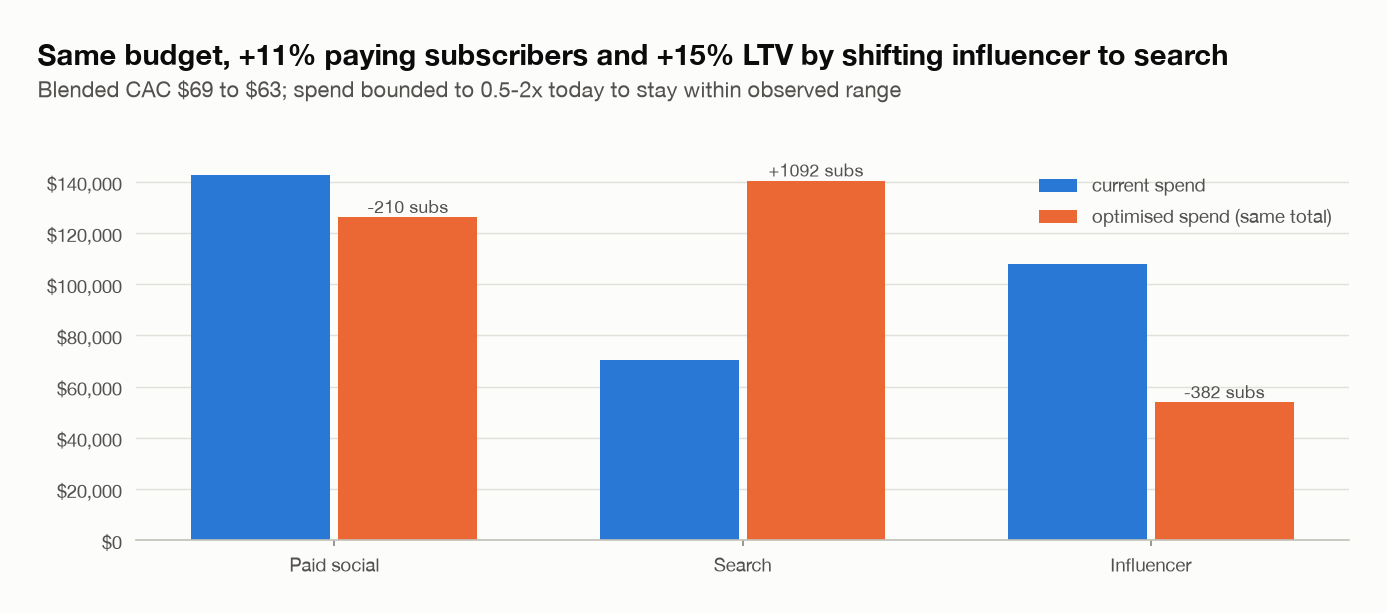

In [25]:
show('19_budget_reallocation')

## 8. Checking against the simulator

Because the data is simulated, I know the true effects. This is a check that the methods
work, not something available with real data.

In [26]:
truth = json.loads(C.GROUND_TRUTH_PATH.read_text())
v = E.compare_to_truth(e1, e2, truth)
pd.DataFrame({k: v[k] for k in ["exp1_d7", "exp2_workouts"]}).T

,estimate,truth,z_error,ci_covers_truth,estimate_cuped,estimate_raw
exp1_d7,0.0329,0.0358,-0.3363,True,NaN,NaN
exp2_workouts,NaN,0.6057,-0.0589,True,0.5940,1.1145


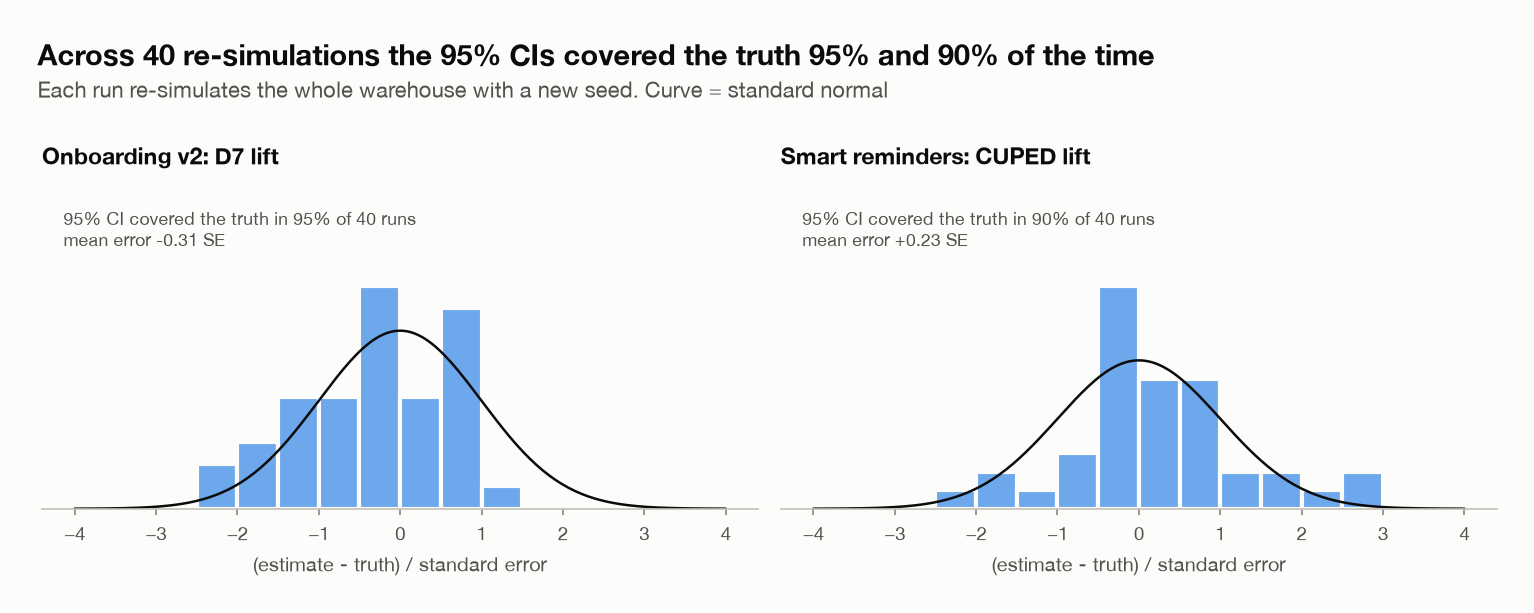

In [27]:
show('20_estimator_coverage')

## Summary

- Ship onboarding v2 on iOS and Android. Fix web exposure logging before re-testing web.
- Ship smart reminders, but plan on the smaller steady-state effect.
- Push users to come back on at least 3 of their first 7 days, and test that directly.
- Use the churn score to target retention offers instead of a blanket discount.
- Move budget from influencer towards search, within the observed spend range.